In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

Selecting previously unselected package fonts-nanum.
(Reading database ... 126101 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


**AIVLE School 미니프로젝트**
### **공공데이터를 활용한 <span style="color:darkgreen">미세먼지 농도</span> 예측**
---

#### **<span style="color:red">[미션 안내]</span>**
* 개인 미션: 미세먼지 농도를 예측하는 머신러닝 모델을 만드세요. ([2-1]부터 [2-10], [3-1]부터 [3-6] 까지 미션 수행)
* 조별 미션: 개인 미션 수행한 내용에 대해 토론하여 발표 준비를 해주세요.

#### **<span style="color:red">[주피터 노트북 파일 안내]</span>**
1. 탐색적 데이터 분석(solution).ipynb: 미션 수행 대상 아님. 제공된 solution을 참고하여 [2-1]부터의 미션 수행을 위한 탐색적 데이터 분석 진행</br>
2. 데이터 전처리.ipynb: [2-1]부터 [2-8] 까지 미션 수행 대상</br>
3. 모델링(머신러닝).ipynb: [3-1]부터 [3-2] 까지 미션 수행 대상. [4-1]~[4-4]는 선택 사항임</br>

#### **<span style="color:red">[데이터 설명]</span>**

* air_2021.csv : 2021년 미세먼지 데이터
* air_2022.csv : 2022년 미세먼지 데이터
* weather_2021.csv : 2021년 날씨 데이터
* weather_2022.csv : 2022년 날씨 데이터
* 학습 데이터: 2021년의 미세먼지 농도 데이터, 테스트 데이터: 2022년의 미세먼지 농도 데이터

# [Step 1] 탐색적 데이터 분석

## **<span style="color:blue">[1-1] 필요한 라이브러리 설치</span>**

In [ ]:
# 필요한 라이브러리 설치 및 임포트
#%pip install pandas seaborn

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

---

## **<span style="color:blue">[1-2] 미세먼지 데이터 불러오기</span>**

* Pandas 라이브러리를 활용해서 'air_2021.csv'파일을 'air_21' 변수에, 'air_2022.csv'파일을 'air_22' 변수에 저장하고 그 데이터를 확인하세요.
* 구분자(sep) : ','
* encoder = 'utf-8'
* index_col = 0

In [ ]:
# 아래에 실습코드를 작성하고 결과를 확인합니다.
# 'air_2021.csv'파일을 'air_21' 변수에, 'air_2022.csv'파일을 'air_22' 변수에 저장
air_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/air_2021(날짜 수정).csv',index_col='측정일시',parse_dates=True)
air_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/air_2022(날짜 수정).csv',index_col='측정일시',parse_dates=True)

### 측정일시를 datetime index로 변환

In [ ]:
air_21

,지역,망,측정소코드,측정소명,SO2,CO,O3,NO2,PM10,PM25,주소
측정일시,,,,,,,,,,,
2021-01-01 01:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.5,0.022,0.016,24.0,14.0,서울 종로구 종로35가길 19
2021-01-01 02:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.6,0.018,0.020,25.0,14.0,서울 종로구 종로35가길 19
2021-01-01 03:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.6,0.013,0.025,27.0,16.0,서울 종로구 종로35가길 19
2021-01-01 04:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.6,0.011,0.027,23.0,13.0,서울 종로구 종로35가길 19
2021-01-01 05:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.6,0.008,0.032,24.0,14.0,서울 종로구 종로35가길 19
...,...,...,...,...,...,...,...,...,...,...,...
2021-12-31 19:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.4,0.026,0.019,25.0,10.0,서울 종로구 종로35가길 19
2021-12-31 20:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.4,0.025,0.020,26.0,8.0,서울 종로구 종로35가길 19
2021-12-31 21:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.4,0.030,0.014,27.0,9.0,서울 종로구 종로35가길 19


In [ ]:
# air_21['측정일시'] = air_21['측정일시'].astype(str)

# # 자정은 다음날 00시여야 하는데 당일날 24시로 되어 있음...
# temp = air_21['측정일시'].str[-2:] == '24'


# air_21.loc[temp, '측정일시'] = ( pd.to_datetime(air_21.loc[temp, '측정일시'].str.slice(0,8), format='%Y%m%d') + pd.Timedelta(days=1)).dt.strftime('%Y%m%d') + '00'

# air_21['측정일시'] = pd.to_datetime(air_21['측정일시'], format='%Y%m%d%H')

# air_21 = air_21.set_index('측정일시')
# air_21 = air_21.sort_index()

In [ ]:
# air_22['측정일시'] = air_22['측정일시'].astype(str)

# # 자정은 다음날 00시여야 하는데 당일날 24시로 되어 있음...
# temp = air_22['측정일시'].str[-2:] == '24'


# air_22.loc[temp, '측정일시'] = (pd.to_datetime(air_22.loc[temp, '측정일시'].str.slice(0,8), format='%Y%m%d') + pd.Timedelta(days=1)).dt.strftime('%Y%m%d') + '00'

# air_22['측정일시'] = pd.to_datetime(air_22['측정일시'], format='%Y%m%d%H')

# air_22 = air_22.set_index('측정일시')

# air_22 = pd.concat([air_22, air_21.tail(1)])
# air_21.drop(air_21.index[-1], inplace=True)

# air_22 = air_22.sort_index()

In [ ]:
air_21.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8759 entries, 2021-01-01 01:00:00 to 2021-12-31 23:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   지역      8759 non-null   object 
 1   망       8759 non-null   object 
 2   측정소코드   8759 non-null   int64  
 3   측정소명    8759 non-null   object 
 4   SO2     8647 non-null   float64
 5   CO      8679 non-null   float64
 6   O3      8662 non-null   float64
 7   NO2     8679 non-null   float64
 8   PM10    8654 non-null   float64
 9   PM25    8662 non-null   float64
 10  주소      8759 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 821.2+ KB


In [ ]:
# air_21 데이터의 head 확인
air_21.head()

,지역,망,측정소코드,측정소명,SO2,CO,O3,NO2,PM10,PM25,주소
측정일시,,,,,,,,,,,
2021-01-01 01:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.5,0.022,0.016,24.0,14.0,서울 종로구 종로35가길 19
2021-01-01 02:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.6,0.018,0.020,25.0,14.0,서울 종로구 종로35가길 19
2021-01-01 03:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.6,0.013,0.025,27.0,16.0,서울 종로구 종로35가길 19
2021-01-01 04:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.6,0.011,0.027,23.0,13.0,서울 종로구 종로35가길 19
2021-01-01 05:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.6,0.008,0.032,24.0,14.0,서울 종로구 종로35가길 19


In [ ]:
# air_21 데이터의 shape 확인
air_21.shape

(8759, 11)

In [ ]:
# air_22 데이터의 head 확인
air_22.head()

,지역,망,측정소코드,측정소명,SO2,CO,O3,NO2,PM10,PM25,주소
측정일시,,,,,,,,,,,
2022-01-01 00:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.4,0.026,0.016,20.0,9.0,서울 종로구 종로35가길 19
2022-01-01 01:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.4,0.026,0.016,23.0,12.0,서울 종로구 종로35가길 19
2022-01-01 02:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.4,0.022,0.020,20.0,9.0,서울 종로구 종로35가길 19
2022-01-01 03:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.5,0.014,0.028,20.0,9.0,서울 종로구 종로35가길 19
2022-01-01 04:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.5,0.016,0.027,19.0,10.0,서울 종로구 종로35가길 19


In [ ]:
# air_22 데이터의 shape 확인
air_22.shape

(2161, 11)

In [ ]:
#air_21.to_csv('air_2021(날짜 수정).csv', encoding='utf-8-sig')

In [ ]:
#air_22.to_csv('air_2022(날짜 수정).csv', encoding='utf-8-sig')

---

## **<span style="color:blue">[1-3] 날씨 데이터 불러오기</span>**

* Pandas 라이브러리를 활용해서 'weather_2021.csv'파일을 'weather_21' 변수에, 'weather_2022.csv'파일을 'weather_22' 변수에 저장하고 그 데이터를 확인하세요.
* 구분자(sep) : ','
* encoder = 'cp949'

In [ ]:
#'weather_2021.csv'파일을 'weather_21' 변수에, 'weather_2022.csv'파일을 'weather_22' 변수에 저장
weather_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/weather_2021.csv', sep=',', encoding='cp949', index_col='일시', parse_dates=True)
weather_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/weather_2022.csv', sep=',', encoding='cp949', index_col='일시', parse_dates=True)

In [ ]:
# 미세먼지 데이터와 같이 날씨 데이터의 head, shape 등을 확인
weather_21.head()

,지점,지점명,기온(°C),기온 QC플래그,강수량(mm),강수량 QC플래그,풍속(m/s),풍속 QC플래그,풍향(16방위),풍향 QC플래그,...,최저운고(100m ),시정(10m),지면상태(지면상태코드),현상번호(국내식),지면온도(°C),지면온도 QC플래그,5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
일시,,,,,,,,,,,,,,,,,,,,,
2021-01-01 01:00:00,108,서울,-8.7,NaN,NaN,NaN,2.4,NaN,270.0,NaN,...,NaN,2000,NaN,NaN,-6.9,NaN,-1.0,-0.8,0.3,1.6
2021-01-01 02:00:00,108,서울,-9.1,NaN,NaN,NaN,1.6,NaN,270.0,NaN,...,NaN,2000,NaN,NaN,-7.1,NaN,-1.1,-0.8,0.3,1.6
2021-01-01 03:00:00,108,서울,-9.3,NaN,NaN,NaN,1.1,NaN,250.0,NaN,...,NaN,2000,NaN,NaN,-7.3,NaN,-1.2,-0.9,0.3,1.6
2021-01-01 04:00:00,108,서울,-9.3,NaN,NaN,NaN,0.3,NaN,0.0,NaN,...,NaN,2000,NaN,NaN,-7.5,NaN,-1.3,-1.0,0.2,1.5
2021-01-01 05:00:00,108,서울,-9.7,NaN,NaN,NaN,1.9,NaN,20.0,NaN,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.3,-1.0,0.2,1.5


In [ ]:
weather_21.shape

(8759, 37)

In [ ]:
weather_22.head()

,지점,지점명,기온(°C),기온 QC플래그,강수량(mm),강수량 QC플래그,풍속(m/s),풍속 QC플래그,풍향(16방위),풍향 QC플래그,...,최저운고(100m ),시정(10m),지면상태(지면상태코드),현상번호(국내식),지면온도(°C),지면온도 QC플래그,5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
일시,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,108,서울,-8.5,NaN,NaN,NaN,1.9,NaN,320,NaN,...,NaN,2000,NaN,NaN,-7.0,NaN,-1.0,-1.0,-0.2,1.0
2022-01-01 01:00:00,108,서울,-9.2,NaN,NaN,NaN,1.8,NaN,270,NaN,...,NaN,2000,NaN,NaN,-7.2,NaN,-1.1,-1.1,-0.2,1.0
2022-01-01 02:00:00,108,서울,-9.5,NaN,NaN,NaN,1.2,NaN,270,NaN,...,NaN,2000,NaN,NaN,-7.5,NaN,-1.3,-1.2,-0.2,1.0
2022-01-01 03:00:00,108,서울,-9.3,NaN,NaN,NaN,1.4,NaN,290,NaN,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.4,-1.2,-0.2,1.0
2022-01-01 04:00:00,108,서울,-9.6,NaN,NaN,NaN,1.7,NaN,340,NaN,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.4,-1.3,-0.3,1.0


In [ ]:
weather_22.shape

(2160, 37)

---

## **<span style="color:blue">[1-4] 데이터 변수 확인</span>**

In [ ]:
# 각 데이터프레임의 info 확인
air_21.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8759 entries, 2021-01-01 01:00:00 to 2021-12-31 23:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   지역      8759 non-null   object 
 1   망       8759 non-null   object 
 2   측정소코드   8759 non-null   int64  
 3   측정소명    8759 non-null   object 
 4   SO2     8647 non-null   float64
 5   CO      8679 non-null   float64
 6   O3      8662 non-null   float64
 7   NO2     8679 non-null   float64
 8   PM10    8654 non-null   float64
 9   PM25    8662 non-null   float64
 10  주소      8759 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 821.2+ KB


In [ ]:
air_22.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2161 entries, 2022-01-01 00:00:00 to 2022-04-01 00:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   지역      2161 non-null   object 
 1   망       2161 non-null   object 
 2   측정소코드   2161 non-null   int64  
 3   측정소명    2161 non-null   object 
 4   SO2     2140 non-null   float64
 5   CO      2140 non-null   float64
 6   O3      2140 non-null   float64
 7   NO2     2140 non-null   float64
 8   PM10    2123 non-null   float64
 9   PM25    2136 non-null   float64
 10  주소      2161 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 202.6+ KB


In [ ]:
weather_21.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8759 entries, 2021-01-01 01:00:00 to 2021-12-31 23:00:00
Data columns (total 37 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   지점             8759 non-null   int64  
 1   지점명            8759 non-null   object 
 2   기온(°C)         8759 non-null   float64
 3   기온 QC플래그       0 non-null      float64
 4   강수량(mm)        949 non-null    float64
 5   강수량 QC플래그      1763 non-null   float64
 6   풍속(m/s)        8757 non-null   float64
 7   풍속 QC플래그       2 non-null      float64
 8   풍향(16방위)       8757 non-null   float64
 9   풍향 QC플래그       2 non-null      float64
 10  습도(%)          8759 non-null   int64  
 11  습도 QC플래그       0 non-null      float64
 12  증기압(hPa)       8759 non-null   float64
 13  이슬점온도(°C)      8759 non-null   float64
 14  현지기압(hPa)      8759 non-null   float64
 15  현지기압 QC플래그     0 non-null      float64
 16  해면기압(hPa)      8759 non-null   float64
 17  해면기압 QC플래그     0

In [ ]:
weather_22.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2160 entries, 2022-01-01 00:00:00 to 2022-03-31 23:00:00
Data columns (total 37 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   지점             2160 non-null   int64  
 1   지점명            2160 non-null   object 
 2   기온(°C)         2160 non-null   float64
 3   기온 QC플래그       0 non-null      float64
 4   강수량(mm)        81 non-null     float64
 5   강수량 QC플래그      382 non-null    float64
 6   풍속(m/s)        2160 non-null   float64
 7   풍속 QC플래그       0 non-null      float64
 8   풍향(16방위)       2160 non-null   int64  
 9   풍향 QC플래그       0 non-null      float64
 10  습도(%)          2160 non-null   int64  
 11  습도 QC플래그       0 non-null      float64
 12  증기압(hPa)       2160 non-null   float64
 13  이슬점온도(°C)      2160 non-null   float64
 14  현지기압(hPa)      2160 non-null   float64
 15  현지기압 QC플래그     0 non-null      float64
 16  해면기압(hPa)      2160 non-null   float64
 17  해면기압 QC플래그     0

In [ ]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.


In [ ]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.


---

## **<span style="color:blue">[1-5] 미세먼지 데이터 분석</span>**

* 데이터 전처리와 모델링을 위해 데이터 분석을 진행해보세요. 시각화 등을 통해 관측치들의 패턴 탐색, 잘못된 자료 탐색, 변수들간의 관계 파악을 할 수 있습니다.

In [ ]:
# # 시각화 한글폰트 설정 (아래 코드를 실행하세요)

# plt.rc('font', family='Malgun Gothic')
# sns.set(font="Malgun Gothic",#"NanumGothicCoding",
#         rc={"axes.unicode_minus":False}, # 마이너스 부호 깨짐 현상 해결
#         style='darkgrid')

### air_21 데이터 분석

In [ ]:
air_21.columns

Index(['지역', '망', '측정소코드', '측정소명', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25',
       '주소'],
      dtype='object')

In [ ]:
air_21[['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].describe()

,SO2,CO,O3,NO2,PM10,PM25
count,8647.000000,8679.000000,8662.000000,8679.000000,8654.000000,8662.000000
mean,0.003385,0.505657,0.029247,0.023346,38.927548,20.467329
std,0.000826,0.209525,0.019709,0.014456,47.472884,16.565413
min,0.001000,0.200000,0.000000,0.003000,3.000000,1.000000
25%,0.003000,0.400000,0.015000,0.012000,18.000000,10.000000
50%,0.003000,0.400000,0.028000,0.019000,30.000000,16.000000
75%,0.004000,0.600000,0.040000,0.031000,46.000000,25.000000
max,0.011000,2.000000,0.137000,0.082000,942.000000,154.000000


#### 히스토그램

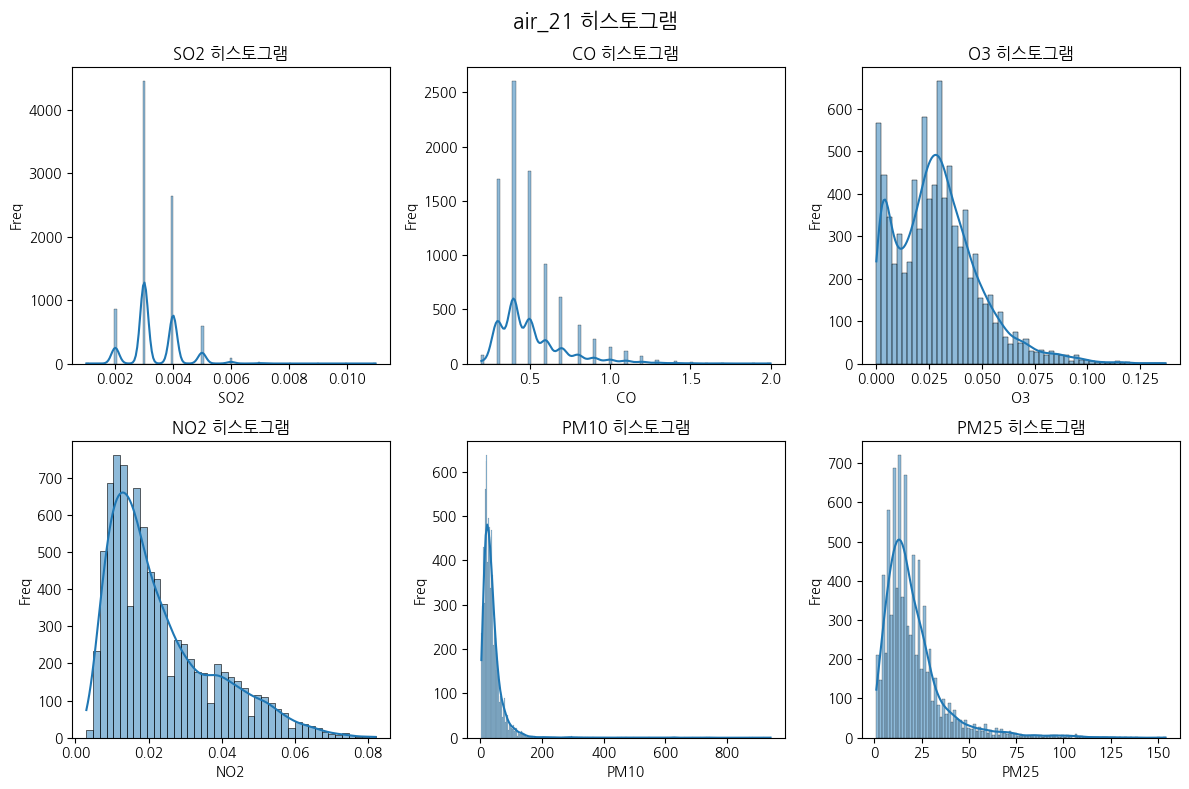

In [ ]:
# air_21 히스토그램
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.histplot(data=air_21, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('air_21 히스토그램', fontsize=15)
plt.tight_layout()
plt.show()

#### 박스 플롯

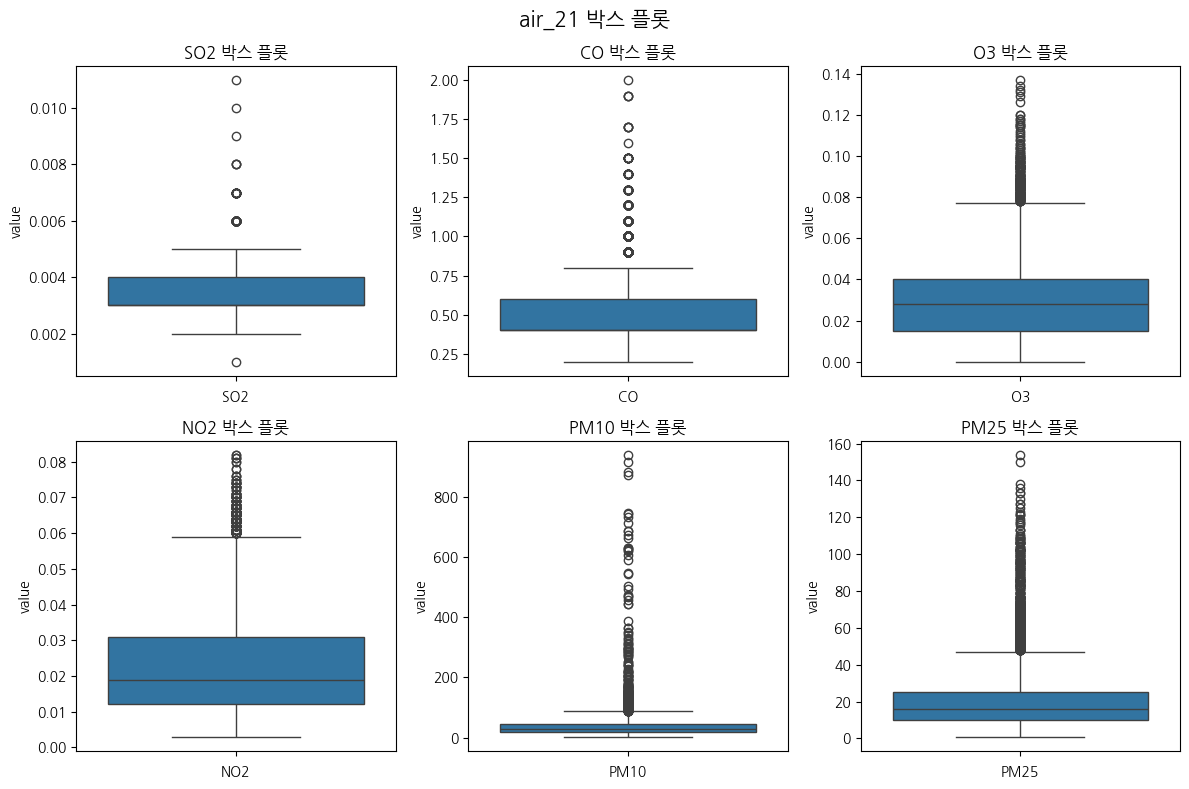

In [ ]:
# air_21 박스 플롯
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.boxplot(data=air_21, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('air_21 박스 플롯', fontsize=15)
plt.tight_layout()
plt.show()

#### 상관관계

In [ ]:
# air_21의 변수간의 상관관계 확인
air_21_corr = air_21[['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].corr()
air_21_corr

,SO2,CO,O3,NO2,PM10,PM25
SO2,1.000000,0.338597,0.110760,0.328997,0.216027,0.378537
CO,0.338597,1.000000,-0.462109,0.866886,0.310607,0.638494
O3,0.110760,-0.462109,1.000000,-0.577561,-0.026723,-0.084646
NO2,0.328997,0.866886,-0.577561,1.000000,0.241140,0.517051
PM10,0.216027,0.310607,-0.026723,0.241140,1.000000,0.674708
PM25,0.378537,0.638494,-0.084646,0.517051,0.674708,1.000000


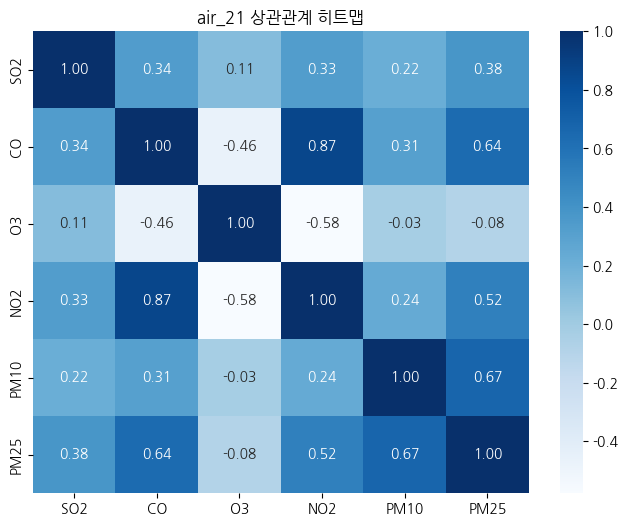

In [ ]:
# air_21의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(air_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("air_21 상관관계 히트맵")
plt.show()

#### 날짜별 데이터

In [ ]:
air_21.head()

,지역,망,측정소코드,측정소명,SO2,CO,O3,NO2,PM10,PM25,주소
측정일시,,,,,,,,,,,
2021-01-01 01:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.5,0.022,0.016,24.0,14.0,서울 종로구 종로35가길 19
2021-01-01 02:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.6,0.018,0.020,25.0,14.0,서울 종로구 종로35가길 19
2021-01-01 03:00:00,서울 종로구,도시대기,111123,종로구,0.002,0.6,0.013,0.025,27.0,16.0,서울 종로구 종로35가길 19
2021-01-01 04:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.6,0.011,0.027,23.0,13.0,서울 종로구 종로35가길 19
2021-01-01 05:00:00,서울 종로구,도시대기,111123,종로구,0.003,0.6,0.008,0.032,24.0,14.0,서울 종로구 종로35가길 19


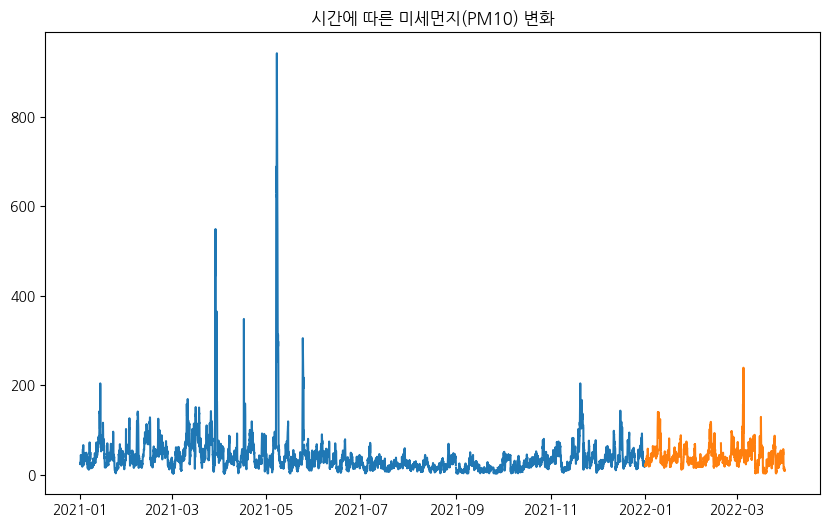

In [ ]:
# air_21['PM10'].plot(figsize=(12,10)).autoscale(axis='x',tight=True);
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(air_21['PM10'])
ax.plot(air_22['PM10'])
ax.set_title('시간에 따른 미세먼지(PM10) 변화')
plt.show()

### air_22 데이터 분석

In [ ]:
air_22.columns

Index(['지역', '망', '측정소코드', '측정소명', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25',
       '주소'],
      dtype='object')

In [ ]:
air_22[['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].describe()

,SO2,CO,O3,NO2,PM10,PM25
count,2140.000000,2140.000000,2140.000000,2140.000000,2123.000000,2136.000000
mean,0.003385,0.576636,0.024674,0.027859,40.553462,27.280431
std,0.000708,0.201342,0.014212,0.015424,23.479599,18.614731
min,0.002000,0.300000,0.002000,0.005000,3.000000,1.000000
25%,0.003000,0.400000,0.012000,0.015000,26.000000,15.000000
50%,0.003000,0.500000,0.026000,0.024000,36.000000,22.000000
75%,0.004000,0.700000,0.035000,0.040000,49.000000,35.000000
max,0.006000,1.400000,0.074000,0.074000,239.000000,121.000000


#### 히스토그램

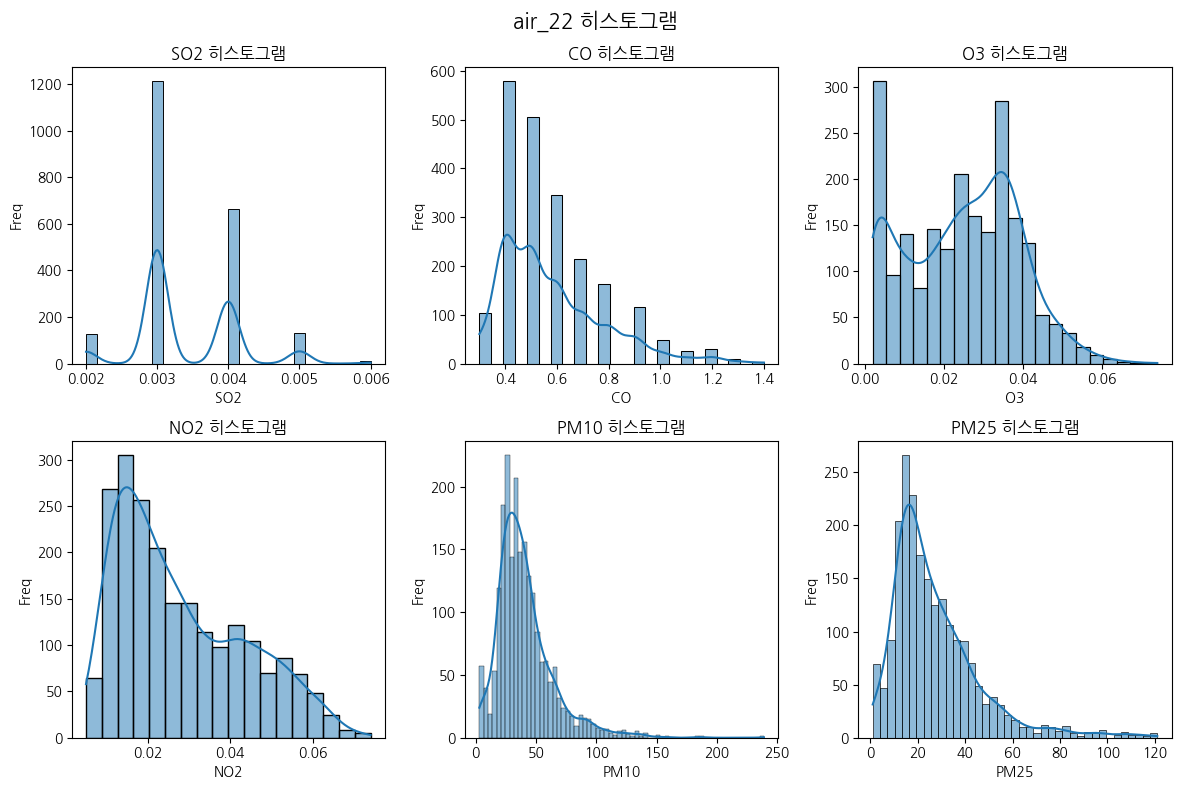

In [ ]:
# air_22 히스토그램
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.histplot(data=air_22, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('air_22 히스토그램', fontsize=15)
plt.tight_layout()
plt.show()

#### 박스 플롯

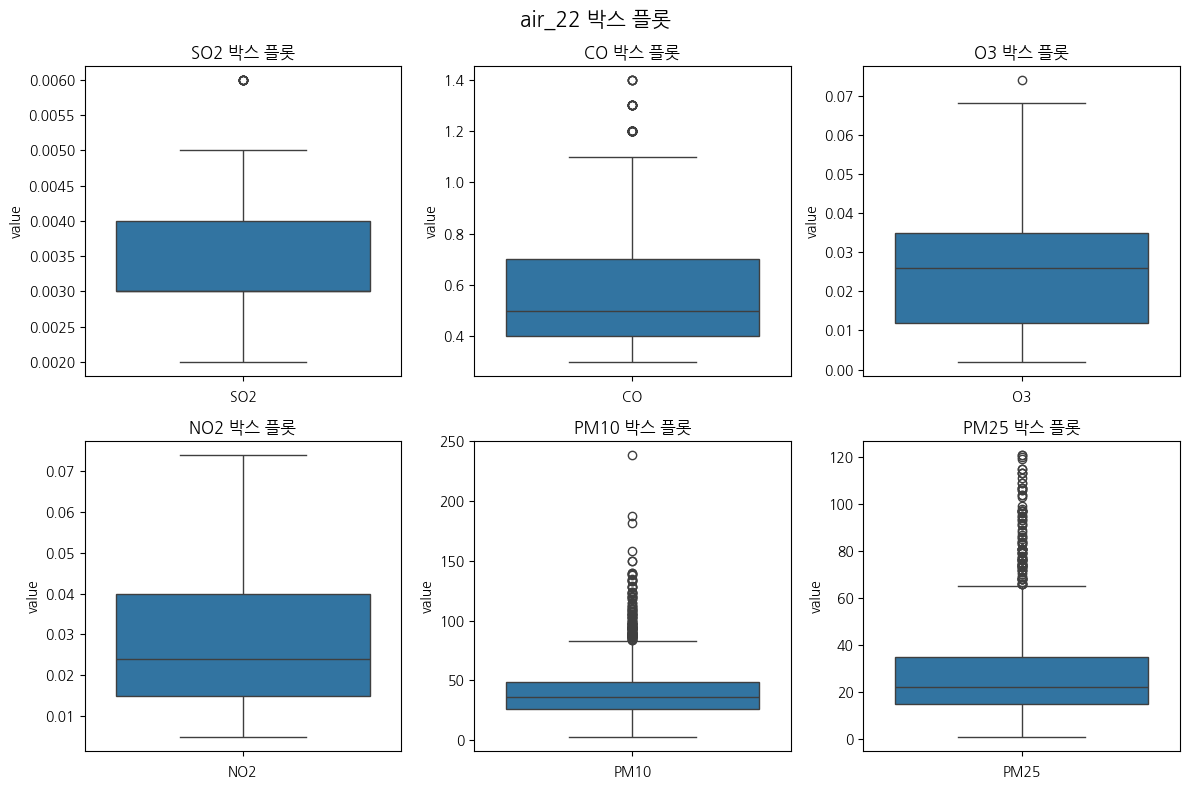

In [ ]:
# air_22 박스 플롯
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.boxplot(data=air_22, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('air_22 박스 플롯', fontsize=15)
plt.tight_layout()
plt.show()

#### 상관관계

In [ ]:
# air_22의 변수간의 상관관계 확인
air_22_corr = air_22[['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].corr()
air_22_corr

,SO2,CO,O3,NO2,PM10,PM25
SO2,1.000000,0.466393,-0.229944,0.448734,0.342488,0.350884
CO,0.466393,1.000000,-0.664001,0.828615,0.505998,0.660516
O3,-0.229944,-0.664001,1.000000,-0.796033,-0.046478,-0.183415
NO2,0.448734,0.828615,-0.796033,1.000000,0.310118,0.405644
PM10,0.342488,0.505998,-0.046478,0.310118,1.000000,0.863643
PM25,0.350884,0.660516,-0.183415,0.405644,0.863643,1.000000


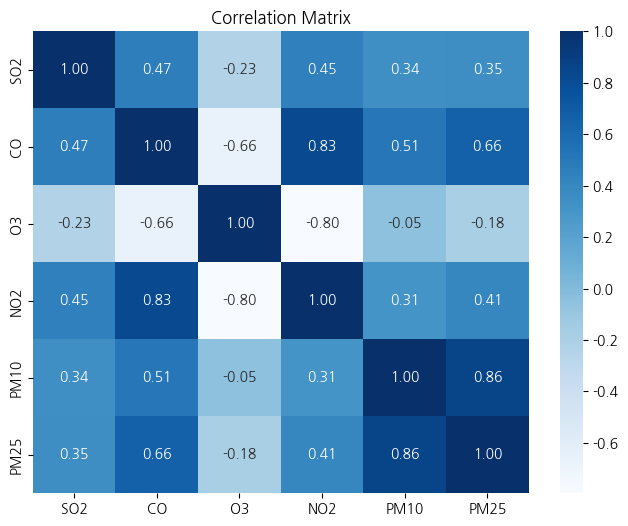

In [ ]:
# air_22의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(air_22_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
# 시각화를 통해 알게된 사실을 정리해봅니다.
# 1.
# 2.
# 3.

---

## **<span style="color:blue">[1-6] 날씨 데이터 분석</span>**

### weather_21 데이터 분석

In [ ]:
weather_21.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8759 entries, 2021-01-01 01:00:00 to 2021-12-31 23:00:00
Data columns (total 37 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   지점             8759 non-null   int64  
 1   지점명            8759 non-null   object 
 2   기온(°C)         8759 non-null   float64
 3   기온 QC플래그       0 non-null      float64
 4   강수량(mm)        949 non-null    float64
 5   강수량 QC플래그      1763 non-null   float64
 6   풍속(m/s)        8757 non-null   float64
 7   풍속 QC플래그       2 non-null      float64
 8   풍향(16방위)       8757 non-null   float64
 9   풍향 QC플래그       2 non-null      float64
 10  습도(%)          8759 non-null   int64  
 11  습도 QC플래그       0 non-null      float64
 12  증기압(hPa)       8759 non-null   float64
 13  이슬점온도(°C)      8759 non-null   float64
 14  현지기압(hPa)      8759 non-null   float64
 15  현지기압 QC플래그     0 non-null      float64
 16  해면기압(hPa)      8759 non-null   float64
 17  해면기압 QC플래그     0

In [ ]:
weather_21.head()

,지점,지점명,기온(°C),기온 QC플래그,강수량(mm),강수량 QC플래그,풍속(m/s),풍속 QC플래그,풍향(16방위),풍향 QC플래그,...,최저운고(100m ),시정(10m),지면상태(지면상태코드),현상번호(국내식),지면온도(°C),지면온도 QC플래그,5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
일시,,,,,,,,,,,,,,,,,,,,,
2021-01-01 01:00:00,108,서울,-8.7,NaN,NaN,NaN,2.4,NaN,270.0,NaN,...,NaN,2000,NaN,NaN,-6.9,NaN,-1.0,-0.8,0.3,1.6
2021-01-01 02:00:00,108,서울,-9.1,NaN,NaN,NaN,1.6,NaN,270.0,NaN,...,NaN,2000,NaN,NaN,-7.1,NaN,-1.1,-0.8,0.3,1.6
2021-01-01 03:00:00,108,서울,-9.3,NaN,NaN,NaN,1.1,NaN,250.0,NaN,...,NaN,2000,NaN,NaN,-7.3,NaN,-1.2,-0.9,0.3,1.6
2021-01-01 04:00:00,108,서울,-9.3,NaN,NaN,NaN,0.3,NaN,0.0,NaN,...,NaN,2000,NaN,NaN,-7.5,NaN,-1.3,-1.0,0.2,1.5
2021-01-01 05:00:00,108,서울,-9.7,NaN,NaN,NaN,1.9,NaN,20.0,NaN,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.3,-1.0,0.2,1.5


In [ ]:
weather_21.isna().sum()

,0
지점,0
지점명,0
기온(°C),0
기온 QC플래그,8759
강수량(mm),7810
강수량 QC플래그,6996
풍속(m/s),2
풍속 QC플래그,8757
풍향(16방위),2
풍향 QC플래그,8757


In [ ]:
weather_21.columns

Index(['지점', '지점명', '기온(°C)', '기온 QC플래그', '강수량(mm)', '강수량 QC플래그', '풍속(m/s)',
       '풍속 QC플래그', '풍향(16방위)', '풍향 QC플래그', '습도(%)', '습도 QC플래그', '증기압(hPa)',
       '이슬점온도(°C)', '현지기압(hPa)', '현지기압 QC플래그', '해면기압(hPa)', '해면기압 QC플래그',
       '일조(hr)', '일조 QC플래그', '일사(MJ/m2)', '일사 QC플래그', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '운형(운형약어)', '최저운고(100m )', '시정(10m)',
       '지면상태(지면상태코드)', '현상번호(국내식)', '지면온도(°C)', '지면온도 QC플래그', '5cm 지중온도(°C)',
       '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)'],
      dtype='object')

In [ ]:
weather_21[['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
            '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
            '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)']].describe()

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C)
count,8759.000000,8757.000000,8757.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,4791.000000,4791.000000,8757.000000,4547.000000,8754.000000,8754.000000
mean,13.739194,2.311328,169.658559,65.589223,12.631236,6.842094,1006.046603,1016.280317,0.458380,1.076706,4.960489,15.161425,14.734304,15.128581
std,10.894786,1.120906,107.549684,18.394276,8.282075,11.736897,7.928167,8.311602,0.438788,0.966440,3.929256,13.537921,12.042066,10.175582
min,-18.500000,0.000000,0.000000,19.000000,0.700000,-27.000000,986.900000,996.500000,0.000000,0.000000,0.000000,1.000000,-12.700000,-4.700000
25%,6.000000,1.500000,50.000000,51.000000,5.900000,-0.400000,999.800000,1009.700000,0.000000,0.230000,0.000000,7.000000,4.300000,5.900000
50%,14.600000,2.200000,200.000000,66.000000,9.700000,6.600000,1006.300000,1016.400000,0.400000,0.790000,6.000000,10.000000,15.400000,15.400000
75%,22.600000,2.900000,270.000000,80.000000,19.900000,17.400000,1012.000000,1022.500000,1.000000,1.800000,9.000000,16.000000,23.600000,24.100000
max,36.300000,8.300000,360.000000,100.000000,32.200000,25.300000,1025.800000,1037.400000,1.000000,3.740000,10.000000,76.000000,56.800000,35.700000


#### 히스토그램

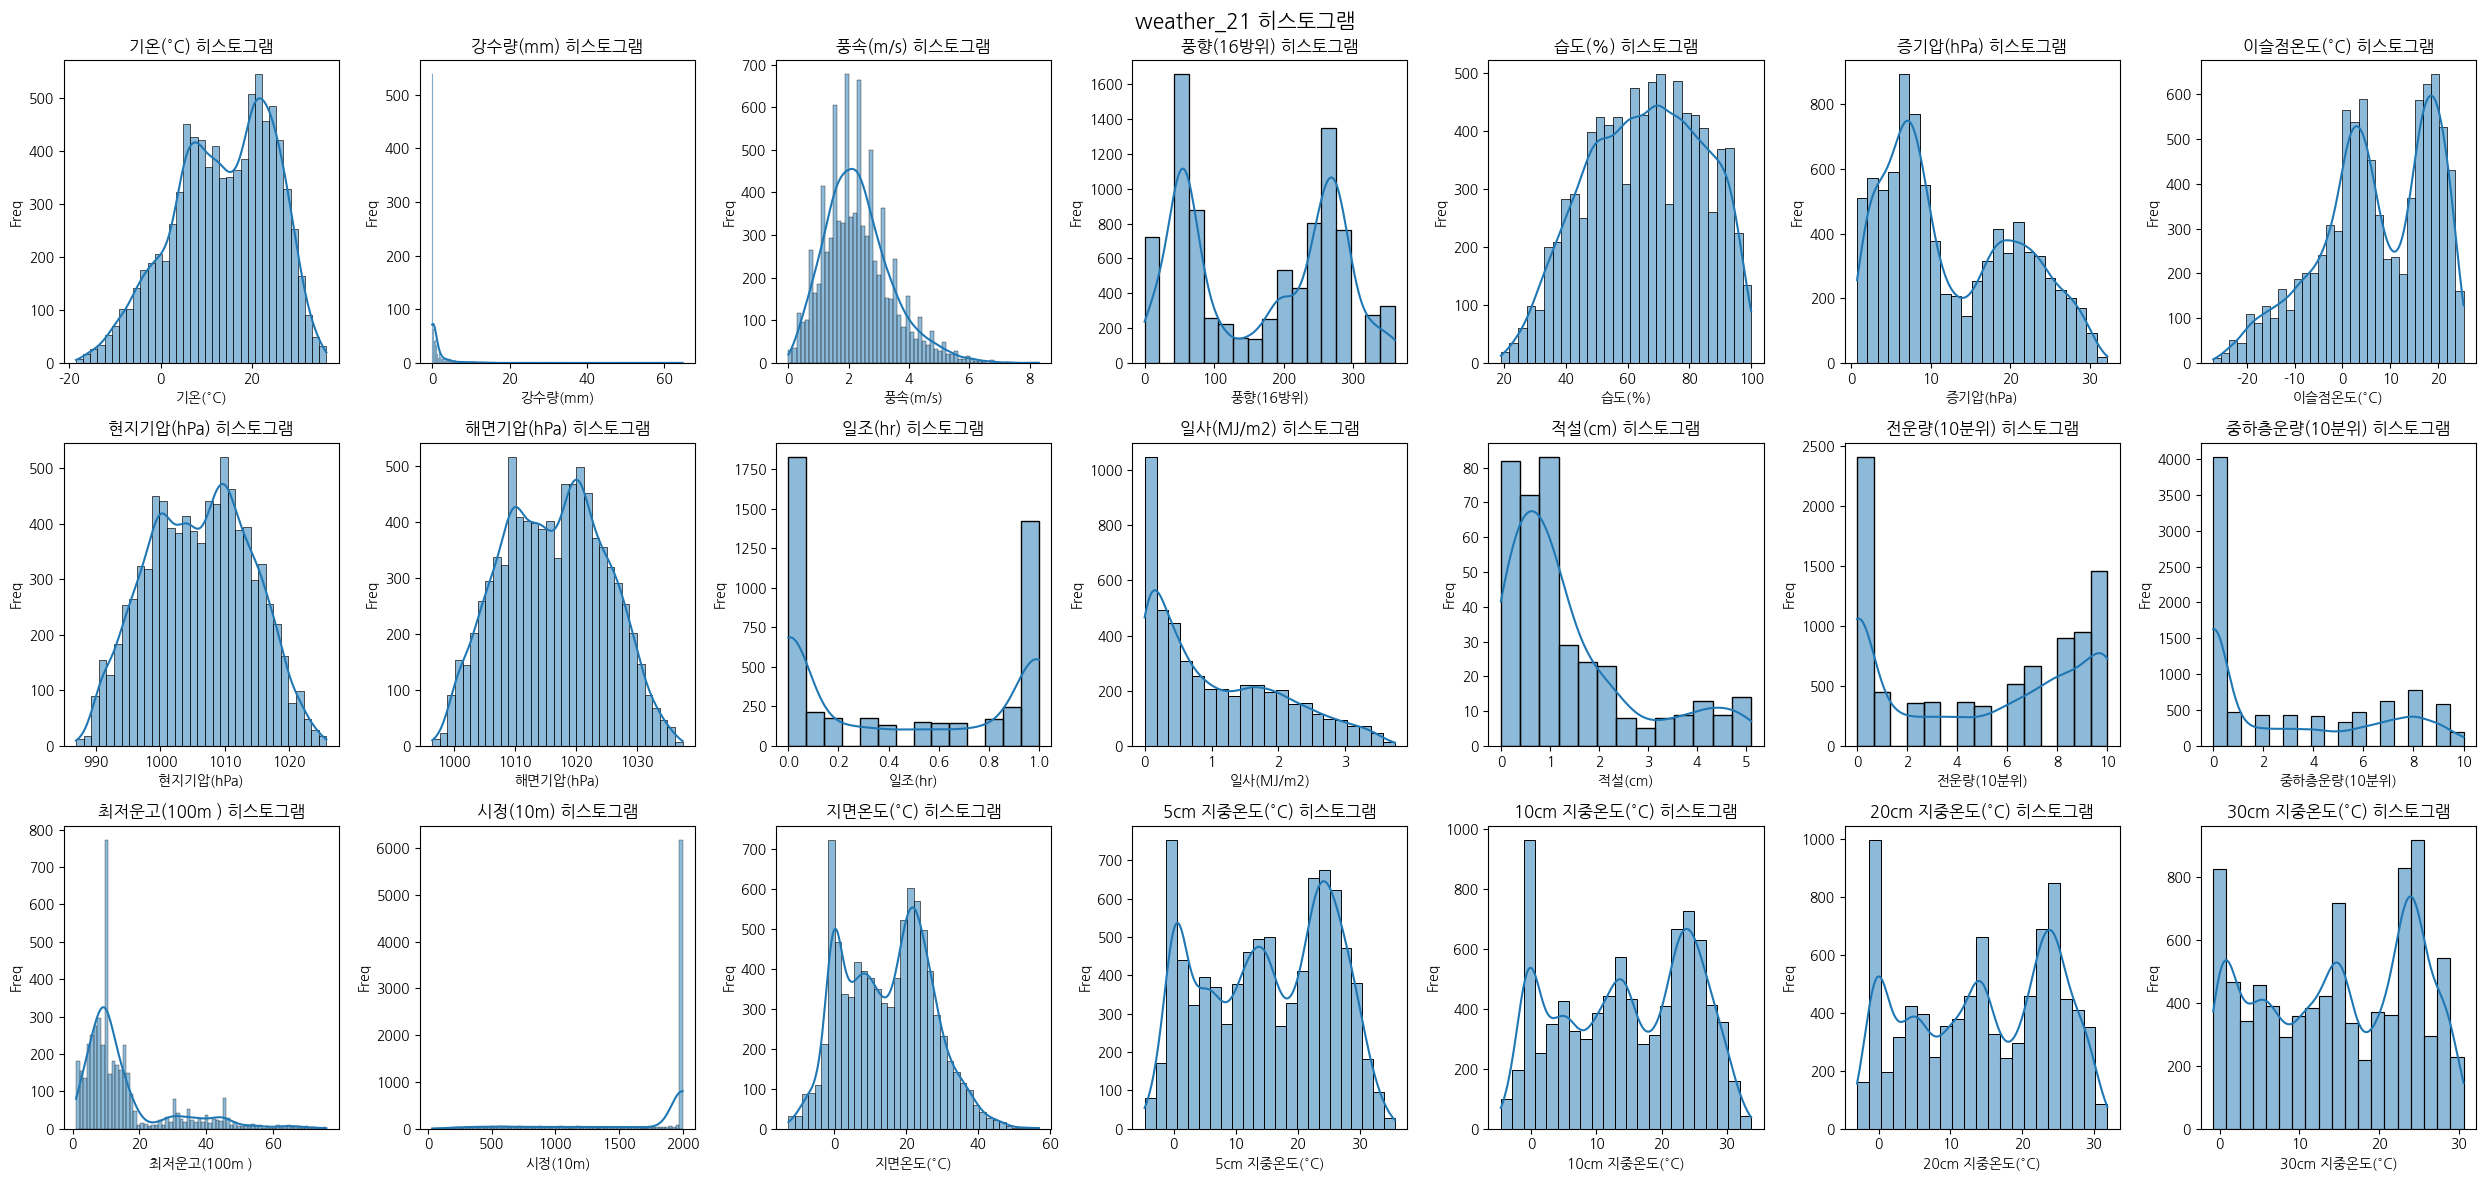

In [ ]:
# weather_21 히스토그램
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.histplot(data=weather_21, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('weather_21 히스토그램', fontsize=15)
plt.tight_layout()
plt.show()

#### 박스 플롯

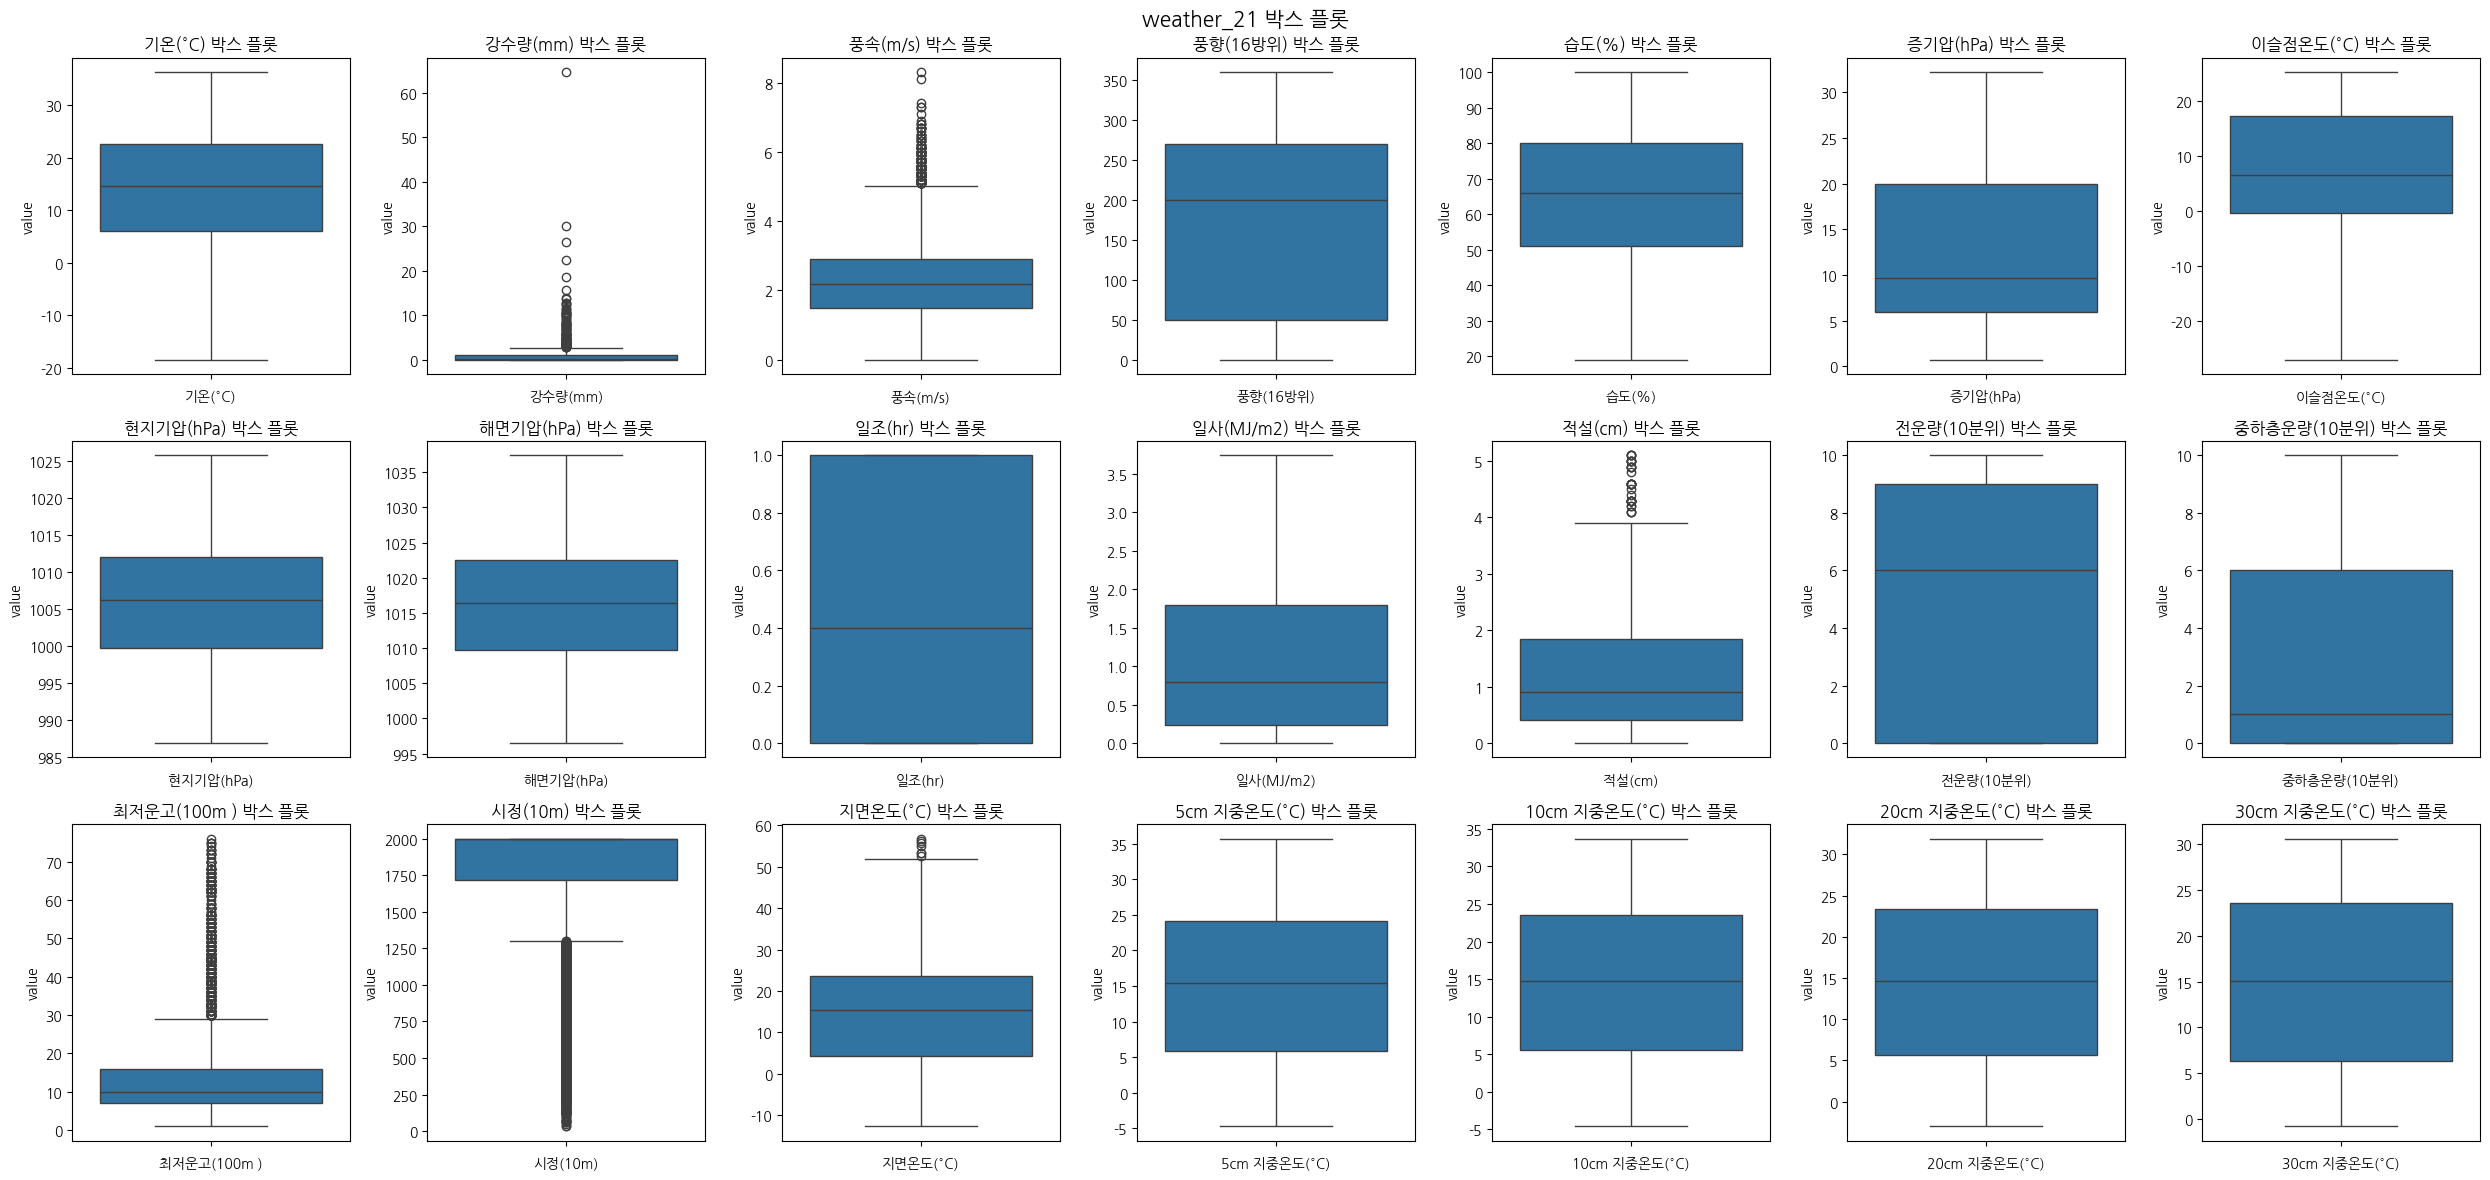

In [ ]:
# air_22 박스 플롯
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.boxplot(data=weather_21, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('weather_21 박스 플롯', fontsize=15)
plt.tight_layout()
plt.show()

#### 상관관계

In [ ]:
# weather_21의 변수간의 상관관계 확인
weather_21_corr = weather_21[['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                              '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
                              '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)']].corr()
weather_21_corr

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C)
기온(°C),1.000000,-0.068998,-0.181061,0.145404,0.881615,0.926402,-0.680025,-0.707822,-0.030577,0.259726,0.307568,0.080681,0.946652,0.951015
풍속(m/s),-0.068998,1.000000,0.172669,-0.285136,-0.147224,-0.168898,-0.046459,-0.041041,0.175146,0.188221,-0.026692,-0.104431,0.015133,-0.067677
풍향(16방위),-0.181061,0.172669,1.000000,-0.200744,-0.188806,-0.231501,0.043715,0.051917,0.116463,0.075342,-0.176713,-0.076933,-0.138250,-0.146987
습도(%),0.145404,-0.285136,-0.200744,1.000000,0.450867,0.501853,-0.359807,-0.354960,-0.561533,-0.505902,0.362256,-0.336348,0.055100,0.220990
증기압(hPa),0.881615,-0.147224,-0.188806,0.450867,1.000000,0.946841,-0.712216,-0.732223,-0.235512,0.009038,0.356878,-0.067908,0.830661,0.912350
이슬점온도(°C),0.926402,-0.168898,-0.231501,0.501853,0.946841,1.000000,-0.726512,-0.748944,-0.257635,0.012966,0.397847,-0.053618,0.846042,0.917517
현지기압(hPa),-0.680025,-0.046459,0.043715,-0.359807,-0.712216,-0.726512,1.000000,0.999241,0.238842,-0.009147,-0.358584,0.196248,-0.646061,-0.703667
해면기압(hPa),-0.707822,-0.041041,0.051917,-0.354960,-0.732223,-0.748944,0.999241,1.000000,0.232820,-0.021364,-0.362082,0.185978,-0.672032,-0.727896
일조(hr),-0.030577,0.175146,0.116463,-0.561533,-0.235512,-0.257635,0.238842,0.232820,1.000000,0.726199,-0.681275,0.036772,0.139113,-0.112766
일사(MJ/m2),0.259726,0.188221,0.075342,-0.505902,0.009038,0.012966,-0.009147,-0.021364,0.726199,1.000000,-0.341380,0.009990,0.500464,0.150922


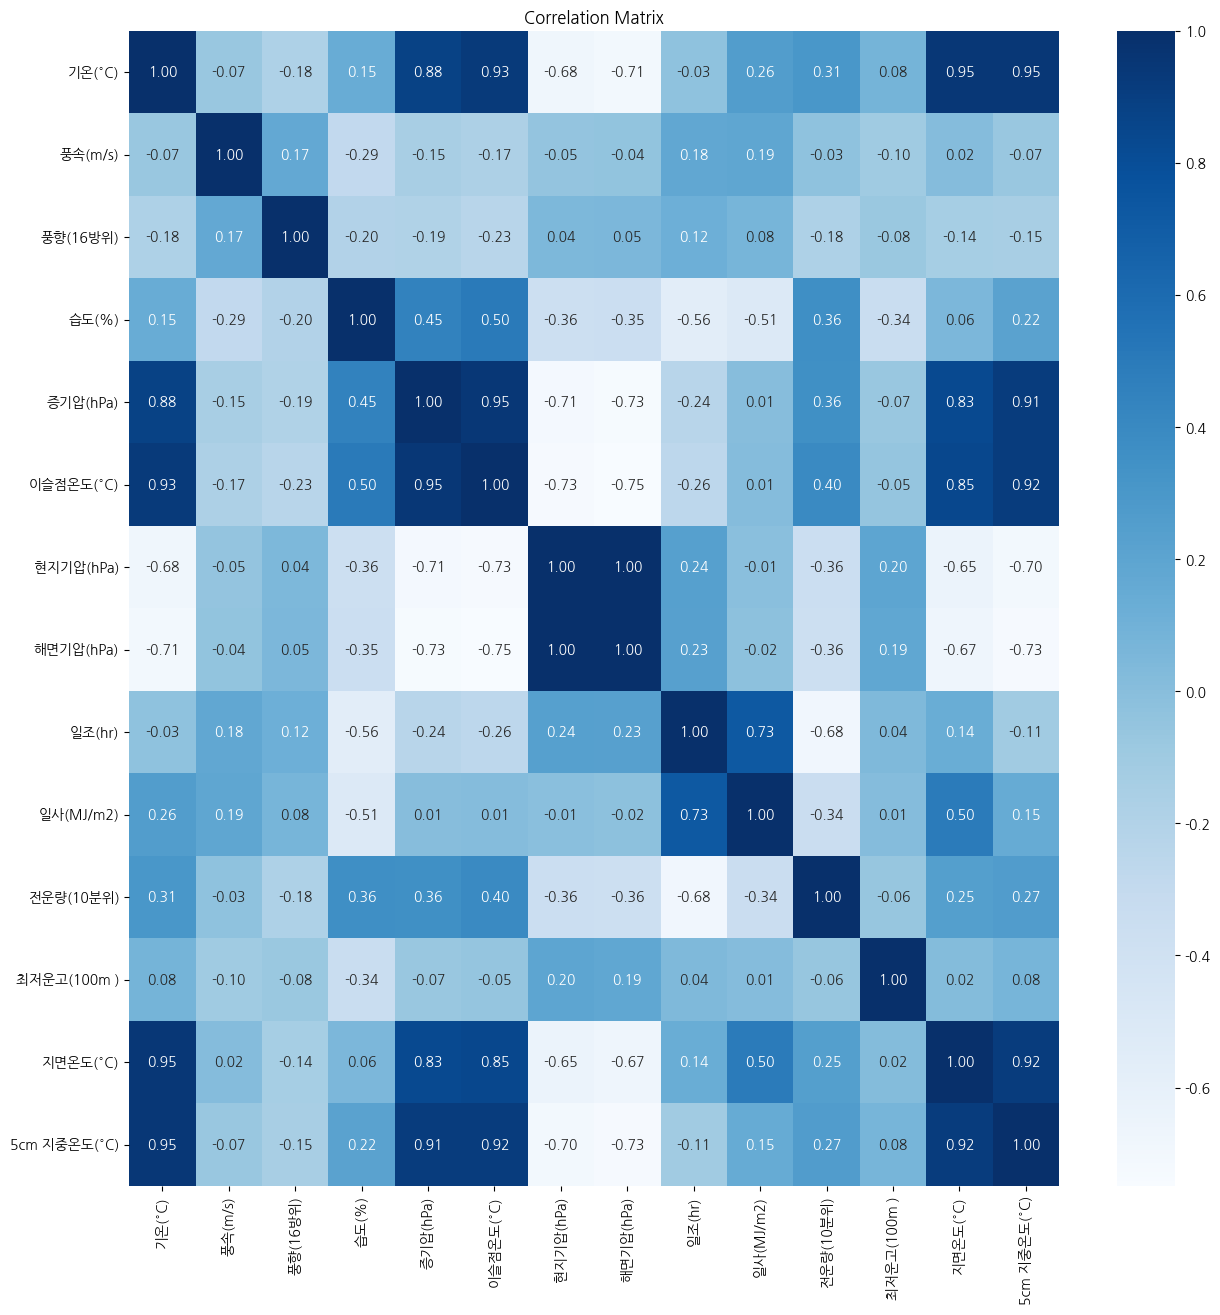

In [ ]:
# weather_21의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(15, 15))
sns.heatmap(weather_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### weather_22 데이터 분석

In [ ]:
weather_22.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2160 entries, 2022-01-01 00:00:00 to 2022-03-31 23:00:00
Data columns (total 37 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   지점             2160 non-null   int64  
 1   지점명            2160 non-null   object 
 2   기온(°C)         2160 non-null   float64
 3   기온 QC플래그       0 non-null      float64
 4   강수량(mm)        81 non-null     float64
 5   강수량 QC플래그      382 non-null    float64
 6   풍속(m/s)        2160 non-null   float64
 7   풍속 QC플래그       0 non-null      float64
 8   풍향(16방위)       2160 non-null   int64  
 9   풍향 QC플래그       0 non-null      float64
 10  습도(%)          2160 non-null   int64  
 11  습도 QC플래그       0 non-null      float64
 12  증기압(hPa)       2160 non-null   float64
 13  이슬점온도(°C)      2160 non-null   float64
 14  현지기압(hPa)      2160 non-null   float64
 15  현지기압 QC플래그     0 non-null      float64
 16  해면기압(hPa)      2160 non-null   float64
 17  해면기압 QC플래그     0

In [ ]:
weather_22.head()

,지점,지점명,기온(°C),기온 QC플래그,강수량(mm),강수량 QC플래그,풍속(m/s),풍속 QC플래그,풍향(16방위),풍향 QC플래그,...,최저운고(100m ),시정(10m),지면상태(지면상태코드),현상번호(국내식),지면온도(°C),지면온도 QC플래그,5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
일시,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,108,서울,-8.5,NaN,NaN,NaN,1.9,NaN,320,NaN,...,NaN,2000,NaN,NaN,-7.0,NaN,-1.0,-1.0,-0.2,1.0
2022-01-01 01:00:00,108,서울,-9.2,NaN,NaN,NaN,1.8,NaN,270,NaN,...,NaN,2000,NaN,NaN,-7.2,NaN,-1.1,-1.1,-0.2,1.0
2022-01-01 02:00:00,108,서울,-9.5,NaN,NaN,NaN,1.2,NaN,270,NaN,...,NaN,2000,NaN,NaN,-7.5,NaN,-1.3,-1.2,-0.2,1.0
2022-01-01 03:00:00,108,서울,-9.3,NaN,NaN,NaN,1.4,NaN,290,NaN,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.4,-1.2,-0.2,1.0
2022-01-01 04:00:00,108,서울,-9.6,NaN,NaN,NaN,1.7,NaN,340,NaN,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.4,-1.3,-0.3,1.0


In [ ]:
weather_22.isna().sum()

,0
지점,0
지점명,0
기온(°C),0
기온 QC플래그,2160
강수량(mm),2079
강수량 QC플래그,1778
풍속(m/s),0
풍속 QC플래그,2160
풍향(16방위),0
풍향 QC플래그,2160


In [ ]:
weather_22[['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
            '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
            '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)']].describe()

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C)
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,1071.000000,1071.000000,2160.000000,743.000000,2160.000000,2160.000000
mean,1.518148,2.430231,212.856481,57.306481,4.319954,-6.569213,1011.898565,1022.689306,0.545005,1.030019,3.842593,12.454913,2.495093,2.196620
std,6.358060,1.164067,100.383875,17.524800,2.626777,7.366634,5.644250,5.874535,0.452274,0.865089,4.058539,9.158550,7.624066,4.069035
min,-11.300000,0.000000,0.000000,17.000000,1.300000,-19.700000,985.000000,995.000000,0.000000,0.000000,0.000000,2.000000,-10.500000,-2.400000
25%,-3.300000,1.600000,160.000000,45.000000,2.300000,-12.600000,1009.200000,1019.800000,0.000000,0.240000,0.000000,7.000000,-2.800000,-0.300000
50%,1.200000,2.300000,250.000000,55.000000,3.500000,-7.500000,1012.400000,1023.300000,0.700000,0.850000,2.000000,10.000000,0.000000,0.200000
75%,6.100000,3.100000,270.000000,69.000000,5.800000,-0.700000,1016.000000,1026.900000,1.000000,1.750000,8.000000,14.000000,7.000000,4.900000
max,19.400000,7.900000,360.000000,100.000000,14.700000,12.700000,1024.000000,1035.300000,1.000000,3.380000,10.000000,60.000000,31.100000,13.100000


#### 히스토그램

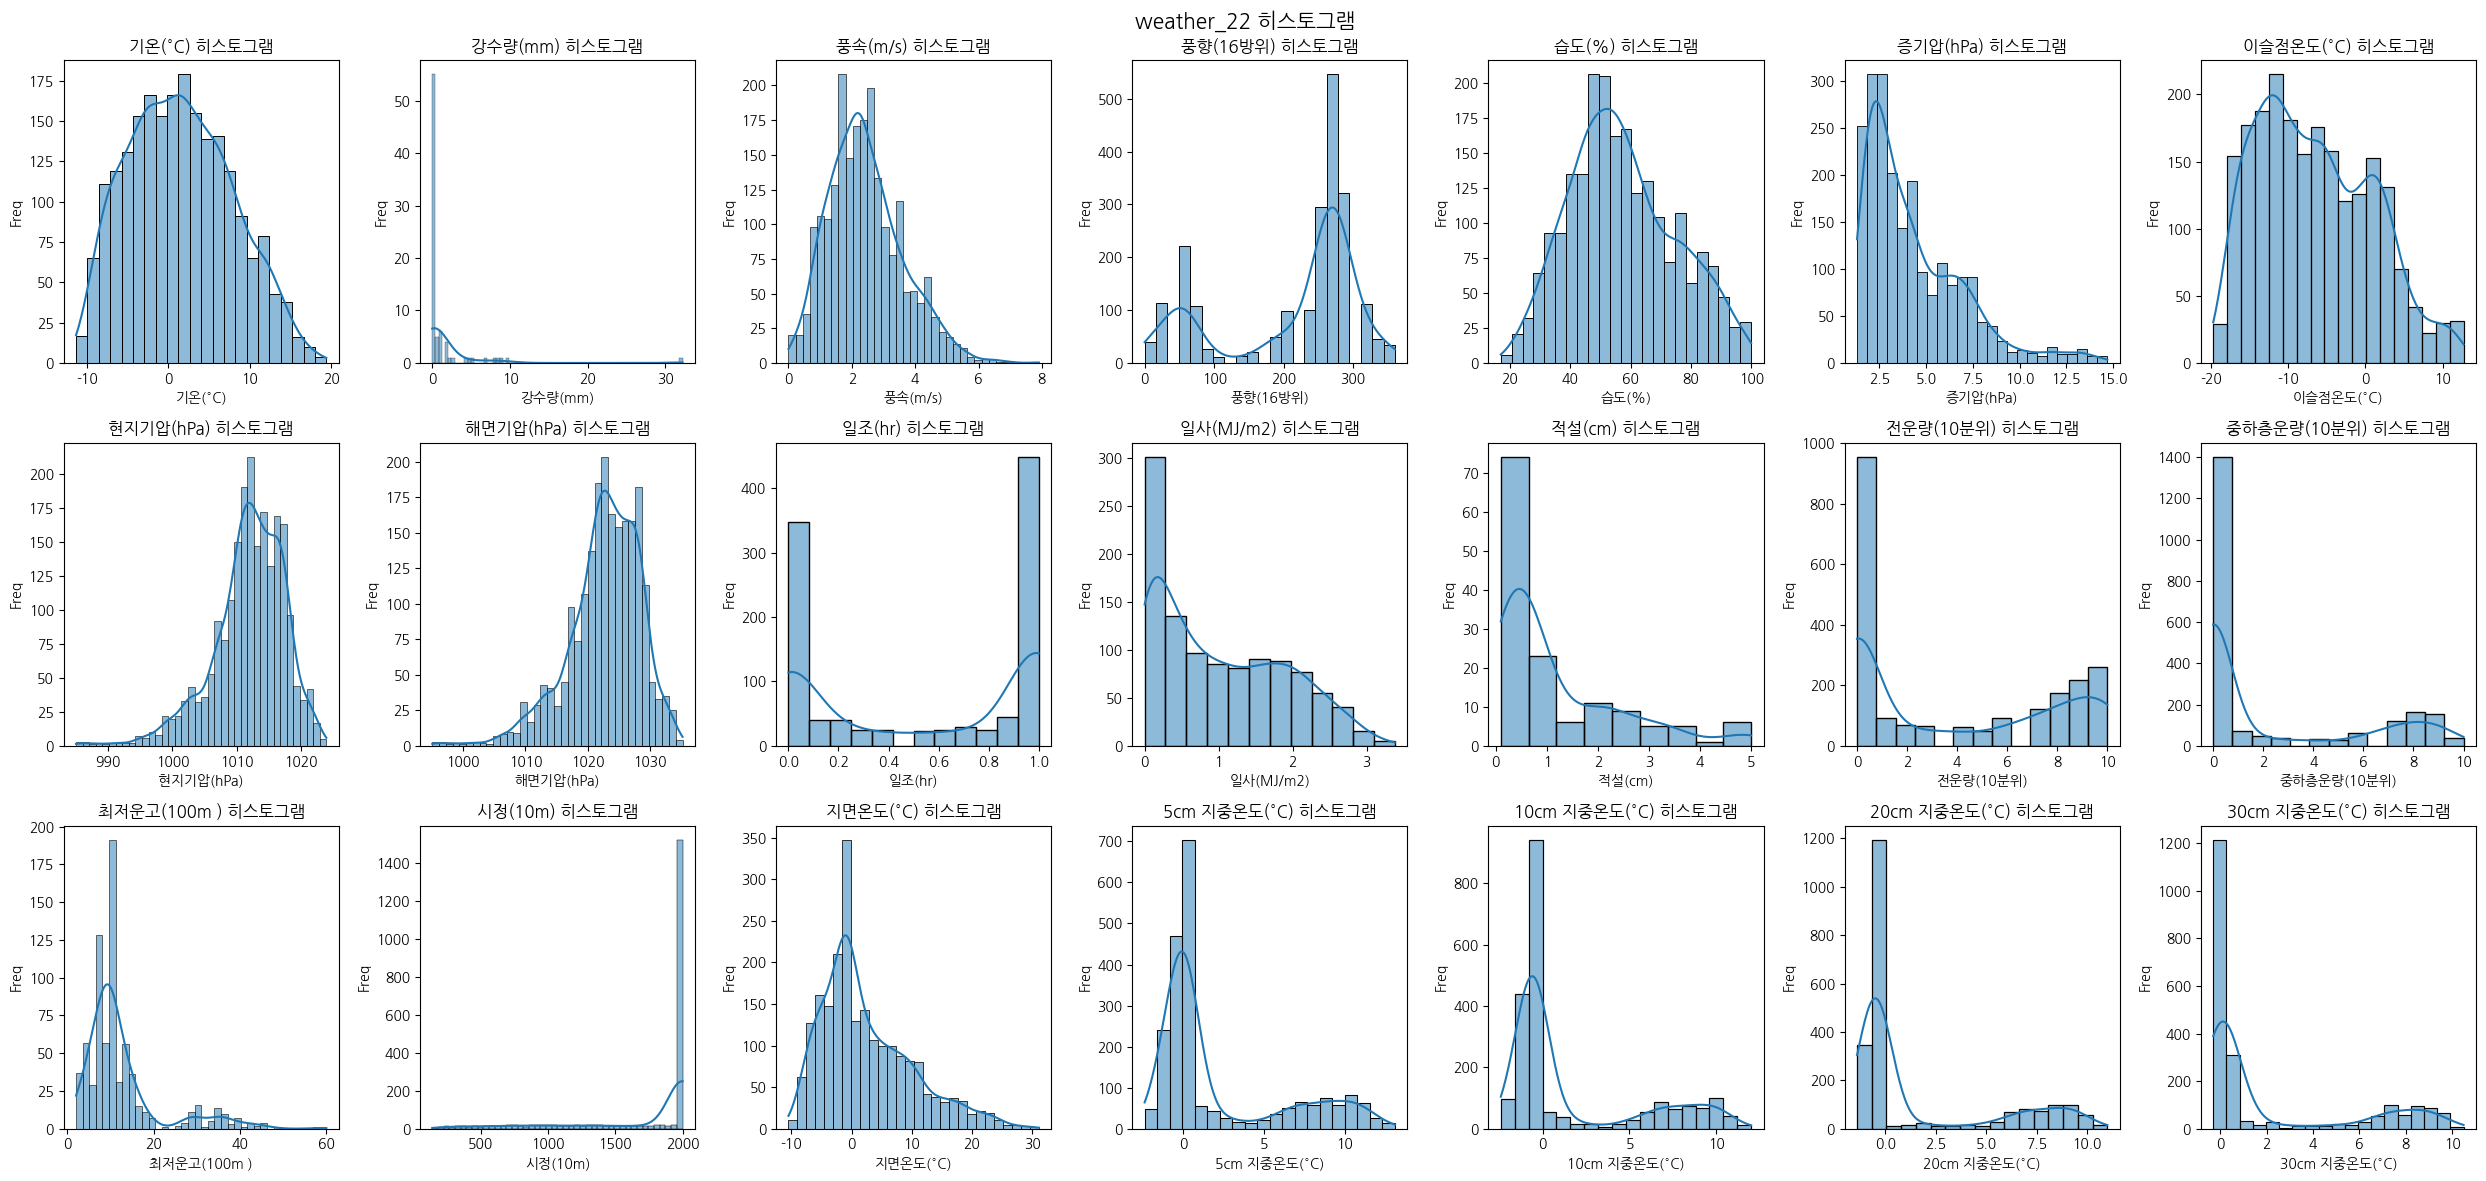

In [ ]:
# weather_22 히스토그램
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.histplot(data=weather_22, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('weather_22 히스토그램', fontsize=15)
plt.tight_layout()
plt.show()

#### 박스 플롯

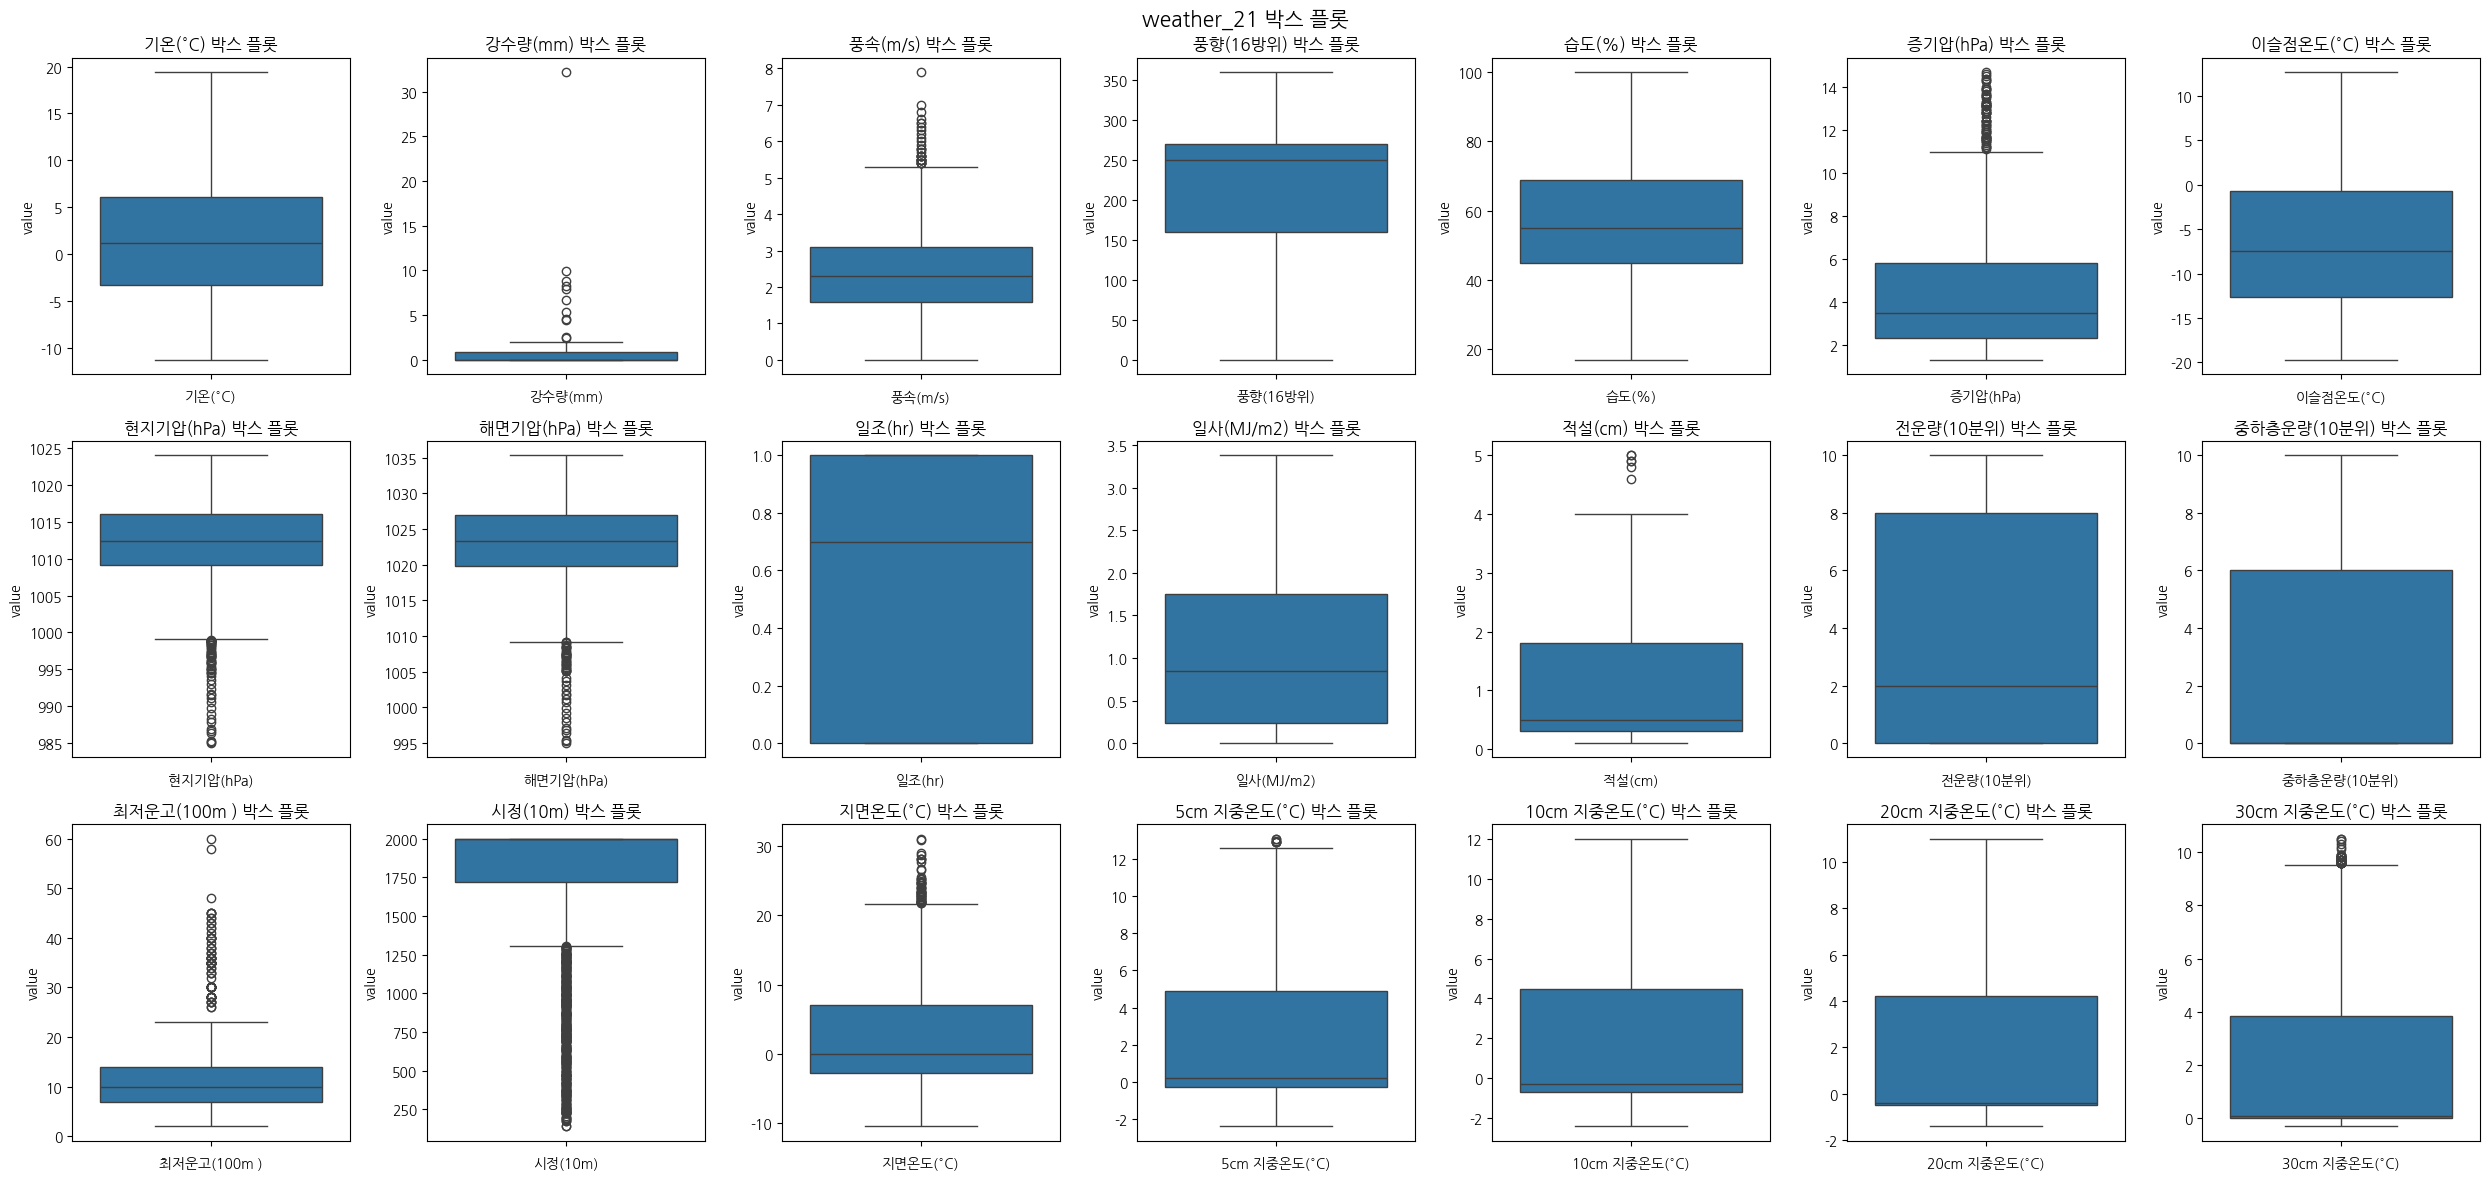

In [ ]:
# weather_22 박스 플롯
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.boxplot(data=weather_22, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('weather_21 박스 플롯', fontsize=15)
plt.tight_layout()
plt.show()

#### 상관관계

In [ ]:
# weather_22의 변수간의 상관관계 확인
weather_22_corr = weather_22[['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                              '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
                              '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)']].corr()
weather_22_corr

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C)
기온(°C),1.000000,0.138356,-0.140791,0.077777,0.779386,0.817643,-0.622577,-0.649923,-0.114630,0.198340,0.450199,-0.099243,0.807113,0.790155
풍속(m/s),0.138356,1.000000,0.165936,-0.196221,0.017092,-0.013171,-0.240350,-0.239571,0.167509,0.254230,0.011370,-0.152645,0.291831,0.088467
풍향(16방위),-0.140791,0.165936,1.000000,-0.222715,-0.206663,-0.241746,0.135344,0.137701,0.256196,0.184896,-0.226442,-0.003076,-0.035764,-0.118708
습도(%),0.077777,-0.196221,-0.222715,1.000000,0.622775,0.628638,-0.380722,-0.373281,-0.583906,-0.557925,0.330343,-0.545520,-0.158087,0.229136
증기압(hPa),0.779386,0.017092,-0.206663,0.622775,1.000000,0.963862,-0.712126,-0.726851,-0.448934,-0.205503,0.528673,-0.364256,0.520974,0.770554
이슬점온도(°C),0.817643,-0.013171,-0.241746,0.628638,0.963862,1.000000,-0.697198,-0.714139,-0.456373,-0.203564,0.543310,-0.369265,0.520548,0.746860
현지기압(hPa),-0.622577,-0.240350,0.135344,-0.380722,-0.712126,-0.697198,1.000000,0.999358,0.380242,0.165718,-0.443465,0.284806,-0.417678,-0.615219
해면기압(hPa),-0.649923,-0.239571,0.137701,-0.373281,-0.726851,-0.714139,0.999358,1.000000,0.375278,0.152665,-0.451133,0.282326,-0.442168,-0.633143
일조(hr),-0.114630,0.167509,0.256196,-0.583906,-0.448934,-0.456373,0.380242,0.375278,1.000000,0.731070,-0.669980,0.120922,0.266927,-0.242651
일사(MJ/m2),0.198340,0.254230,0.184896,-0.557925,-0.205503,-0.203564,0.165718,0.152665,0.731070,1.000000,-0.355036,0.112319,0.700504,0.005484


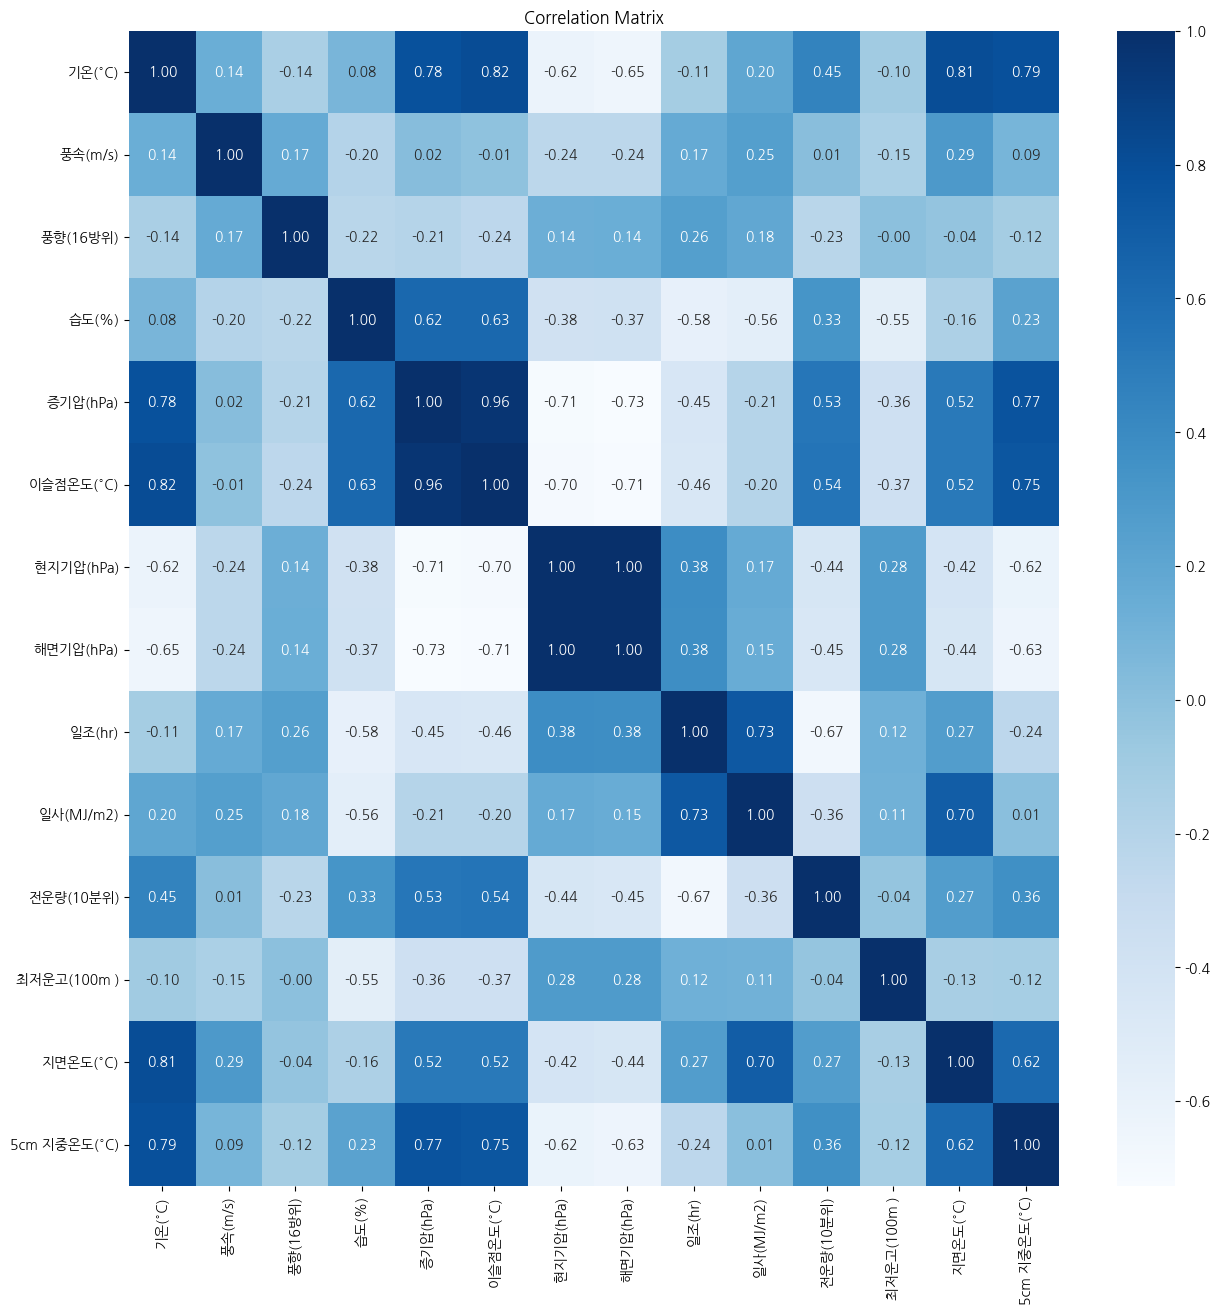

In [ ]:
# weather_22의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(15, 15))
sns.heatmap(weather_22_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
# 시각화를 통해 알게된 사실을 정리해봅니다.
# 1.
# 2.
# 3.